<a href="https://colab.research.google.com/github/siaelkhattat/SuperResolution/blob/main/notebooks/05_diffusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import os
if not os.path.exists("/content/SuperResolution"):
    !git clone https://github.com/siaelkhattat/SuperResolution.git
%cd /content/SuperResolution
!git pull
!pip install -q -r requirements.txt
import sys; sys.path.insert(0, ".")
from src.utils.colab_setup import (mount_drive, setup_data, restore_results_from_drive,
                                   verify_repo, load_generator, sync_results_to_drive, CKPT_DIR)
mount_drive(); setup_data(); restore_results_from_drive(); verify_repo()

/content/SuperResolution
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 5 (delta 4), reused 5 (delta 4), pack-reused 0 (from 0)
Unpacking objects: 100% (5/5), 409 bytes | 409.00 KiB/s, done.
From https://github.com/siaelkhattat/SuperResolution
   1754a3e..40be66d  main       -> origin/main
Updating 1754a3e..40be66d
Fast-forward
 src/data/dataset.py | 2 +-
 1 file changed, 1 insertion(+), 1 deletion(-)
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data already present, nothing to do.
Repo OK.


In [10]:
!python -m src.train.train_diffusion --config configs/diffusion.yaml

caching train images: 100% 300/300 [00:31<00:00,  9.58it/s]
U-Net params (M): 5.865363
it 200 | loss 0.03823 | 0.8 min
it 400 | loss 0.02791 | 1.6 min
it 600 | loss 0.02486 | 2.5 min
it 800 | loss 0.02246 | 3.4 min
it 1000 | loss 0.02179 | 4.2 min
it 1200 | loss 0.02162 | 5.1 min
it 1400 | loss 0.02084 | 6.0 min
it 1600 | loss 0.02108 | 6.9 min
it 1800 | loss 0.02077 | 7.7 min
it 2000 | loss 0.02057 | 8.6 min
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. Yo

In [11]:
import pandas as pd
from src.models.bicubic import Bicubic
from src.eval.evaluate import get_datasets, evaluate_method
from src.utils.colab_setup import load_generator, CKPT_DIR

datasets = get_datasets()
crop_only = {"DIV2K_test_c512": datasets["DIV2K_test_c512"]}
edsr, _ = load_generator("edsr_lite_best"); gan, _ = load_generator("edsr_gan_best")
for name, m, fname in [("bicubic", Bicubic(4), "bicubic"), ("edsr_lite_100ep", edsr, "edsr_lite_100ep"), ("edsr_gan", gan, "edsr_gan")]:
    evaluate_method(name, m, crop_only).to_csv(f"results/tables/per_image_{fname}_c512.csv", index=False)

bicubic on DIV2K_test_c512:   0%|          | 0/50 [00:00<?, ?it/s]

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth


edsr_gan on DIV2K_test_c512: 100%|██████████| 50/50 [00:08<00:00,  5.97it/s]


In [12]:
from src.models.diffusion import load_diffusion_sr
from src.eval.evaluate import summarize

diff, ck = load_diffusion_sr(CKPT_DIR / "diffusion_best.pth", steps=10)
print("best iteration:", ck["it"], "| val PSNR:", round(ck["val_psnr"], 3), "| val LPIPS:", round(ck["val_lpips"], 4))
df = evaluate_method("diffusion_ddim10", diff, datasets)
df.to_csv("results/tables/per_image_diffusion_ddim10.csv", index=False)

names = ["bicubic", "edsr_lite_100ep", "edsr_gan"]
parts = [pd.read_csv(f"results/tables/per_image_{n}.csv") for n in names]
parts += [pd.read_csv(f"results/tables/per_image_{n}_c512.csv") for n in names]
summary = summarize(pd.concat(parts + [df]))
summary.to_csv("results/tables/summary_all_4methods.csv", index=False); summary

best iteration: 18000 | val PSNR: 29.959 | val LPIPS: 0.1791


diffusion_ddim10 on DIV2K_test_c512: 100%|██████████| 50/50 [01:08<00:00,  1.37s/it]


,method,dataset,psnr,ssim,lpips
0,bicubic,DIV2K_test,28.4458,0.8023,0.3886
1,bicubic,DIV2K_test_c512,27.0069,0.7368,0.4651
2,bicubic,Set14,26.2199,0.7263,0.4433
3,bicubic,Set5,28.6347,0.8265,0.3419
4,diffusion_ddim10,DIV2K_test_c512,27.4417,0.7575,0.2174
5,diffusion_ddim10,Set14,27.1448,0.7520,0.1940
6,diffusion_ddim10,Set5,30.2543,0.8727,0.1160
7,edsr_gan,DIV2K_test,28.9823,0.8248,0.2007
8,edsr_gan,DIV2K_test_c512,27.6373,0.7683,0.2469
9,edsr_gan,Set14,27.2050,0.7645,0.2230


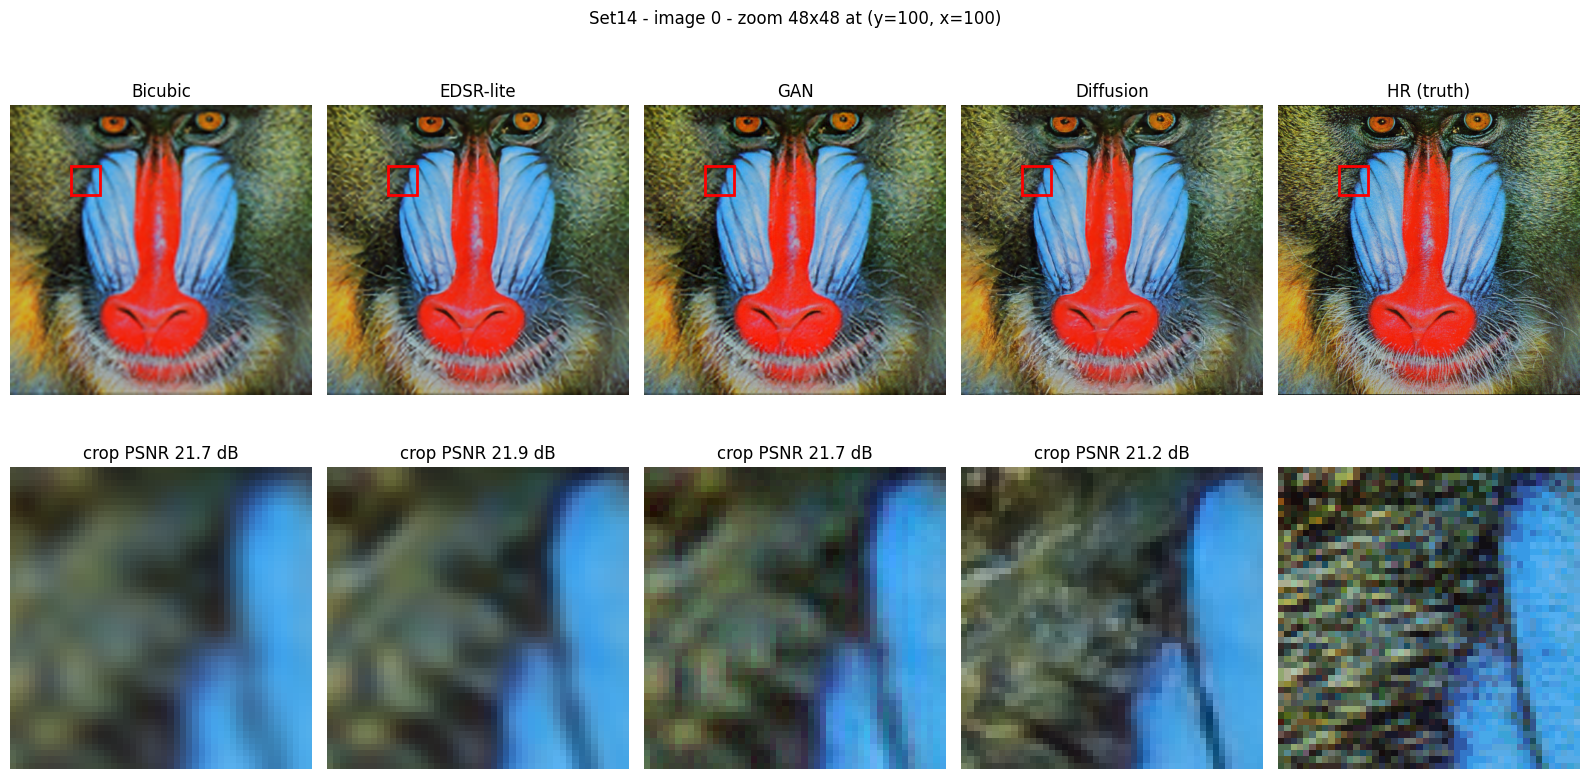

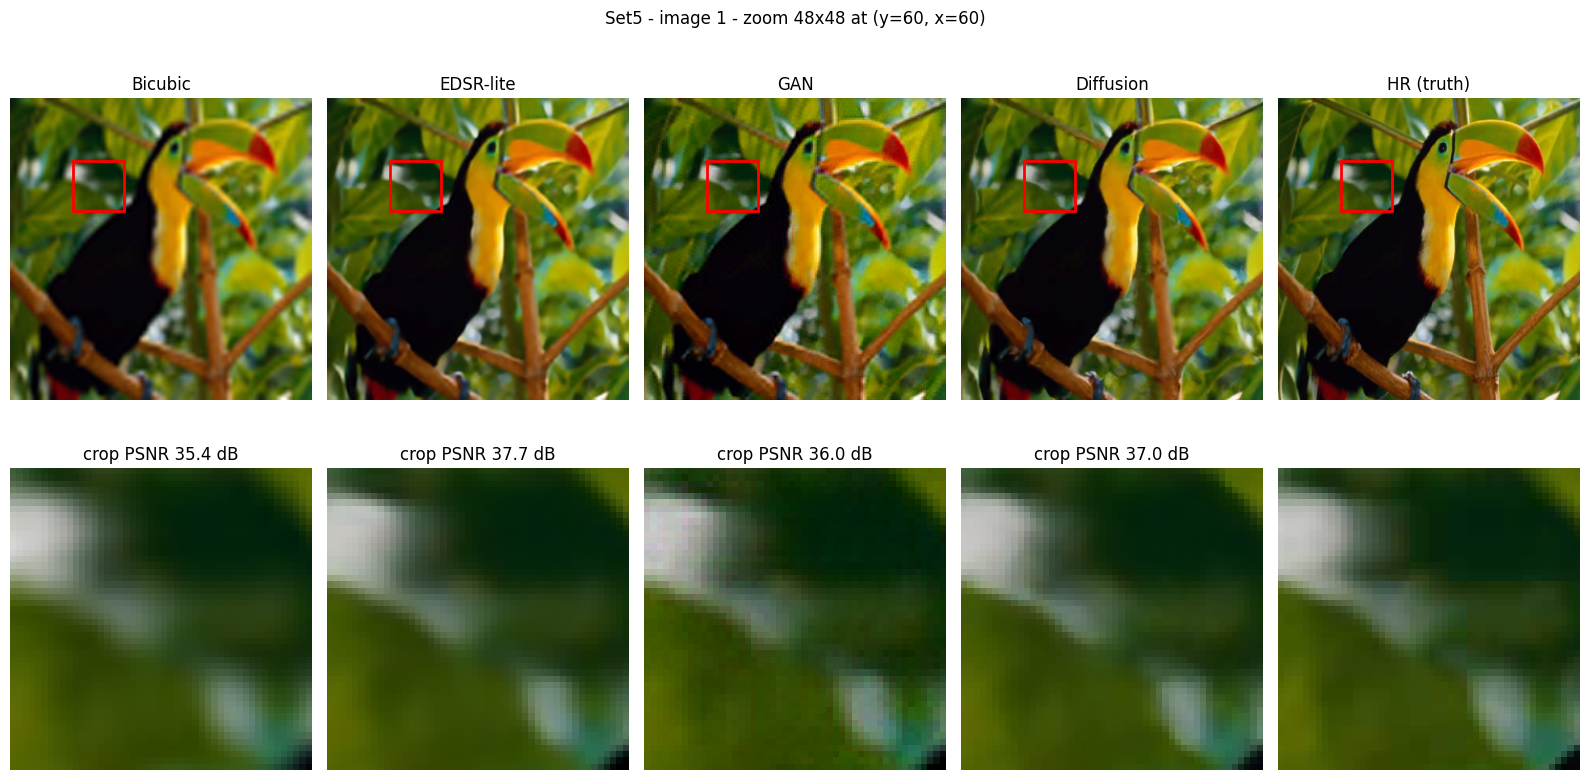

KeyError: 'DIV2K_test'

In [15]:
import torch, matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from pathlib import Path
from src.eval.evaluate import get_datasets, to_np
from src.eval.metrics import psnr

device = "cuda"
edsr, gan = edsr.to(device).eval(), gan.to(device).eval()
bicubic = Bicubic(4).to(device)
datasets = get_datasets()
METHODS = {"Bicubic": bicubic, "EDSR-lite": edsr, "GAN": gan,"Diffusion": diff.to("cuda")}

@torch.no_grad()
def zoom_compare(dname, idx, box, save_as):
    """box = (y, x, size) in HR pixel coordinates."""
    lr, hr = datasets[dname][idx]
    y, x, s = box
    outs = {k: to_np(m(lr[None].to(device))[0]) for k, m in METHODS.items()}
    outs["HR (truth)"] = to_np(hr)
    fig, ax = plt.subplots(2, 5, figsize=(16, 8.5))
    for j, (title, im) in enumerate(outs.items()):
        ax[0, j].imshow(im); ax[0, j].set_title(title); ax[0, j].axis("off")
        ax[0, j].add_patch(Rectangle((x, y), s, s, fill=False, ec="red", lw=2))
        crop = im[y:y + s, x:x + s]
        ax[1, j].imshow(crop, interpolation="nearest"); ax[1, j].axis("off")
        if title != "HR (truth)":
            ax[1, j].set_title(f"crop PSNR {psnr(crop, outs['HR (truth)'][y:y+s, x:x+s], shave=0):.1f} dB")
    fig.suptitle(f"{dname} - image {idx} - zoom {s}x{s} at (y={y}, x={x})")
    plt.tight_layout()
    Path("results/figures").mkdir(parents=True, exist_ok=True)
    plt.savefig(f"results/figures/{save_as}.png", dpi=150); plt.show()

# Try several images and crops: the box is (y, x, size) in HR pixels
zoom_compare("Set14", 0, (100, 100, 48), "zoom_set14_0")
zoom_compare("Set5", 1, (60, 60, 48), "zoom_set5_1")
zoom_compare("DIV2K_test", 0, (400, 600, 64), "zoom_div2k_0")

sync_results_to_drive()

In [16]:

!zip -r colab_outputs5.zip  results/tables results/figures
from google.colab import files
files.download("colab_outputs5.zip")


  adding: results/tables/ (stored 0%)
  adding: results/tables/speed_edsr_lite.csv (deflated 40%)
  adding: results/tables/per_image_edsr_gan.csv (deflated 59%)
  adding: results/tables/per_image_diffusion_steps.csv (deflated 62%)
  adding: results/tables/per_image_edsr_lite_100ep_c512.csv (deflated 66%)
  adding: results/tables/per_image_edsr_lite_100ep.csv (deflated 62%)
  adding: results/tables/train_log_edsr_gan.csv (deflated 57%)
  adding: results/tables/per_image_bicubic.csv (deflated 59%)
  adding: results/tables/speed_bicubic.csv (deflated 38%)
  adding: results/tables/summary_bicubic.csv (deflated 22%)
  adding: results/tables/per_image_bicubic_c512.csv (deflated 63%)
  adding: results/tables/summary_all.csv (deflated 47%)
  adding: results/tables/speed_all.csv (deflated 58%)
  adding: results/tables/summary_all_4methods.csv (deflated 57%)
  adding: results/tables/per_image_edsr_gan_c512.csv (deflated 63%)
  adding: results/tables/train_log_diffusion.csv (deflated 47%)
  addin

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
rows = []
for s in (5, 10, 20, 50):
    diff.steps = s
    r = evaluate_method(f"diffusion_ddim{s}", diff, {k: datasets[k] for k in ["Set5", "Set14"]})
    rows.append(r)
steps_df = pd.concat(rows)
steps_df.to_csv("results/tables/per_image_diffusion_steps.csv", index=False)
summarize(steps_df)

diffusion_ddim50 on Set14: 100%|██████████| 14/14 [01:25<00:00,  6.14s/it]


,method,dataset,psnr,ssim,lpips
0,diffusion_ddim10,Set14,27.144800,0.7520,0.1940
1,diffusion_ddim10,Set5,30.254299,0.8727,0.1160
2,diffusion_ddim20,Set14,26.803301,0.7372,0.1800
3,diffusion_ddim20,Set5,29.815201,0.8614,0.1008
4,diffusion_ddim5,Set14,27.630301,0.7701,0.2313
5,diffusion_ddim5,Set5,30.877800,0.8852,0.1442
6,diffusion_ddim50,Set14,26.516600,0.7221,0.1687
7,diffusion_ddim50,Set5,29.439301,0.8478,0.0928


In [14]:
from src.eval.benchmark_speed import benchmark
diff.steps = 10
gpu = benchmark("diffusion_ddim10", diff, sizes=((64, 64), (256, 256)), device="cuda", warmup=2, runs=10)
cpu = benchmark("diffusion_ddim10", diff, sizes=((64, 64),), device="cpu", warmup=1, runs=3)
speed = pd.concat([pd.read_csv("results/tables/speed_all.csv"), gpu, cpu], ignore_index=True)
speed.to_csv("results/tables/speed_all.csv", index=False); speed

,method,device,lr_size,ms_median,ms_std,peak_mem_mb,params_m
0,bicubic,cuda,64x64,0.159,0.006,29.6,0.000
1,bicubic,cuda,256x256,2.119,0.124,52.8,0.000
2,bicubic,cpu,64x64,15.137,2.577,NaN,0.000
3,bicubic,cpu,256x256,50.859,1.101,NaN,0.000
4,edsr_lite_100ep,cuda,64x64,3.809,0.419,61.1,0.927
5,edsr_lite_100ep,cuda,256x256,49.521,0.358,556.8,0.927
6,edsr_lite_100ep,cpu,64x64,215.330,6.209,NaN,0.927
7,edsr_lite_100ep,cpu,256x256,3001.723,483.709,NaN,0.927
8,edsr_gan,cuda,64x64,5.371,1.144,57.6,0.927
9,edsr_gan,cuda,256x256,49.953,0.370,553.3,0.927
